# LEP-19 — Identifier les facteurs présentant les associations les plus fortes avec l’espérance de vie

**Projet** : WHO Life Expectancy  
**Sprint** : 4  
**Période étudiée** : 2000–2015  
**Sources** : résultats annuels de LEP-17 et de LEP-18

## Question analytique

Quels indicateurs sanitaires, économiques et éducatifs présentent les
associations les plus fortes avec l’espérance de vie ? Leur sens et leur
intensité restent-ils stables d’une année à l’autre ?

## Démarche

1. Réunir les coefficients annuels de Spearman et les effectifs de LEP-17 et LEP-18.
2. Vérifier la période, les indicateurs et le nombre de pays inclus dans les calculs.
3. Classer les indicateurs selon la valeur absolue de leur corrélation médiane.
4. Visualiser et interpréter le classement en tenant compte de la variation
   annuelle des coefficients et de la couverture des données.

Chaque coefficient résume une comparaison entre pays pour une même année.
Le groupe de pays utilisé peut varier selon l’indicateur et l’année.

### 1. Charger et réunir les résultats de LEP-17 et LEP-18

Nous réunissons les coefficients annuels de Spearman et les effectifs
des analyses sanitaires, économiques et éducatives. Chaque ligne correspond
à un indicateur et à une année. La colonne `dimension` permet de retrouver
l’origine des résultats dans le tableau commun.

In [7]:
# Bibliothèques
from zipfile import ZipFile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
from pathlib import Path

import pandas as pd

dossier_tables = Path("../reports/tables")

# Charger les deux CSV et identifier la dimension de chaque indicateur.
resultats_lep17 = pd.read_csv(
    dossier_tables / "lep17_correlations_annuelles.csv"
).assign(dimension="Sanitaire")

resultats_lep18 = pd.read_csv(
    dossier_tables / "lep18_correlations_annuelles.csv"
).assign(dimension="Économique et éducative")

# Empiler les résultats des deux analyses.
resultats_lep19 = pd.concat(
    [resultats_lep17, resultats_lep18],
    ignore_index=True,
)

print("Dimensions :", resultats_lep19.shape)
display(resultats_lep19.groupby("dimension").size())
display(resultats_lep19.head())

Dimensions : (192, 5)


dimension
Sanitaire                  144
Économique et éducative     48
dtype: int64

,year,indicateur,spearman,nb_pays,dimension
0,2000,adult_mortality,-0.574159,183,Sanitaire
1,2000,diphtheria,0.642302,180,Sanitaire
2,2000,hepatitis_b,0.130579,84,Sanitaire
3,2000,hiv_aids,-0.731420,183,Sanitaire
4,2000,infant_mortality_per_1000_live_births,-0.944998,183,Sanitaire


### 2. Vérifier la couverture des résultats annuels

Nous vérifions que chacun des 12 indicateurs dispose d’un résultat pour
chaque année de 2000 à 2015, que les couples indicateur–année sont uniques
et que les coefficients de Spearman sont renseignés et compris entre −1 et 1.

Nous vérifions également que chaque résultat indique le nombre de pays
inclus dans le calcul. Cet effectif peut varier selon l’indicateur et l’année.

In [9]:
# Compter les années distinctes représentées pour chaque indicateur.
annees_par_indicateur = resultats_lep19.groupby("indicateur")["year"].nunique()

# Vérifier la structure des résultats et les valeurs utilisées pour le classement.
controles_lep19 = pd.Series({
    "12 indicateurs": len(annees_par_indicateur) == 12,
    "Période exacte de 2000 à 2015": set(resultats_lep19["year"]) == set(range(2000, 2016)),
    "16 années pour chaque indicateur": annees_par_indicateur.eq(16).all(),
    "Aucun doublon indicateur–année": not resultats_lep19.duplicated(
        subset=["indicateur", "year"]
    ).any(),
    "Coefficients renseignés et compris entre −1 et 1": (
        resultats_lep19["spearman"].between(-1, 1).all()
    ),
    "Au moins deux pays par coefficient": resultats_lep19["nb_pays"].ge(2).all(),
}, name="validé")

display(controles_lep19)

12 indicateurs                                      True
Période exacte de 2000 à 2015                       True
16 années pour chaque indicateur                    True
Aucun doublon indicateur–année                      True
Coefficients renseignés et compris entre −1 et 1    True
Au moins deux pays par coefficient                  True
Name: validé, dtype: bool

### 3. Classer les indicateurs selon leur corrélation médiane

Pour chaque indicateur, nous calculons la médiane et la moyenne des 16 corrélations
annuelles de Spearman. Le classement utilise la valeur absolue de cette
médiane pour comparer la force des associations positives et négatives.
Nous conservons le coefficient signé pour indiquer le sens de la relation.

Les coefficients minimum et maximum montrent comment l’association varie
d’une année à l’autre. Les effectifs minimum et maximum indiquent combien
de pays ont contribué aux calculs annuels.

In [10]:
# Résumer les 16 résultats annuels de chaque indicateur.
classement_lep19 = (
    resultats_lep19.groupby(["indicateur", "dimension"], as_index=False)
    .agg(
        spearman_median=("spearman", "median"),
        spearman_moyen=("spearman", "mean"),
        spearman_min=("spearman", "min"),
        spearman_max=("spearman", "max"),
        pays_min=("nb_pays", "min"),
        pays_max=("nb_pays", "max"),
    )
    .sort_values(
        "spearman_median",
        key=lambda coefficients: coefficients.abs(),
        ascending=False,
    )
    .reset_index(drop=True)
)

classement_lep19.insert(0, "rang", classement_lep19.index + 1)

display(classement_lep19.round(3))

,rang,indicateur,dimension,spearman_median,spearman_moyen,spearman_min,spearman_max,pays_min,pays_max
0,1,under_five_mortality_per_1000_live_births,Sanitaire,-0.946,-0.946,-0.954,-0.940,183,191
1,2,infant_mortality_per_1000_live_births,Sanitaire,-0.941,-0.941,-0.945,-0.935,183,191
2,3,gni_per_capita_ppp_2021,Économique et éducative,0.858,0.859,0.846,0.879,180,189
3,4,gdp,Économique et éducative,0.857,0.854,0.832,0.882,181,189
4,5,expected_years_of_schooling,Économique et éducative,0.816,0.816,0.808,0.824,174,190
5,6,hiv_aids,Sanitaire,-0.776,-0.771,-0.792,-0.731,183,191
6,7,adult_mortality,Sanitaire,-0.703,-0.666,-0.771,-0.548,183,183
7,8,overweight_adults_pct_oms,Sanitaire,0.629,0.620,0.524,0.677,183,189
8,9,diphtheria,Sanitaire,0.562,0.583,0.540,0.666,180,191
9,10,polio,Sanitaire,0.541,0.549,0.508,0.604,180,191


#### Lecture du classement des associations

La mortalité avant cinq ans et la mortalité infantile occupent les deux
premiers rangs, avec des corrélations médianes de **−0,946** et **−0,941**.
Leurs coefficients varient peu d’une année à l’autre. Ces associations
s’interprètent en tenant compte du fait que l’espérance de vie est elle-même
calculée à partir de la mortalité aux différents âges.

Le RNB par habitant (**+0,858**) et le PIB par habitant (**+0,857**)
présentent des associations positives de force comparable. Le nombre
attendu d’années de scolarisation suit (**+0,816**) et présente la plage
annuelle la plus étroite parmi les trois indicateurs économiques et éducatifs.

L’incidence déclarée de la rougeole présente l’association médiane la plus
faible en valeur absolue (**−0,238**), avec des coefficients annuels allant
de **−0,567 à −0,108**. La couverture vaccinale contre l’hépatite B varie
aussi sensiblement selon l’année, et les calculs reposent sur **84 à
180 pays**. La plage des coefficients et les effectifs complètent donc
le classement par médiane.

Le classement décrit la force des associations observées entre pays.
Il ne mesure pas l’effet propre de chaque indicateur sur l’espérance de vie.

### 4. Visualiser les associations avec l’espérance de vie

Le graphique reprend l’ordre du classement. Chaque point représente la
médiane des 16 corrélations annuelles de Spearman, et chaque segment relie
le minimum et le maximum observés de 2000 à 2015. L’axe commun de −1 à +1
permet de comparer les associations positives et négatives sur la même échelle.

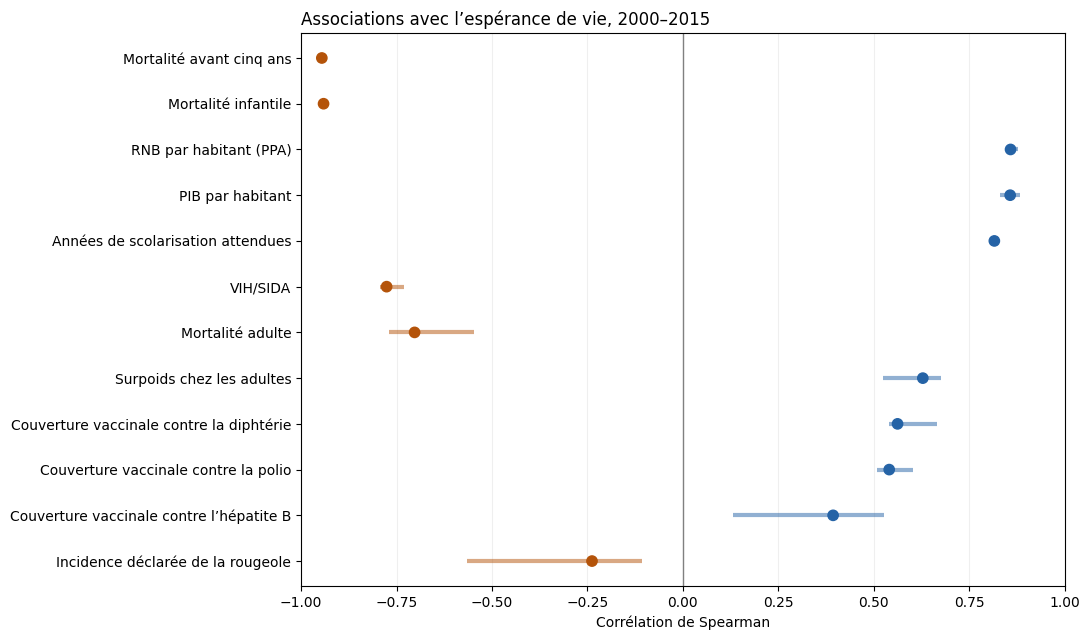

In [11]:
import matplotlib.pyplot as plt

# Remplacer les noms de colonnes par des libellés lisibles.
libelles_lep19 = {
    "under_five_mortality_per_1000_live_births": "Mortalité avant cinq ans",
    "infant_mortality_per_1000_live_births": "Mortalité infantile",
    "gni_per_capita_ppp_2021": "RNB par habitant (PPA)",
    "gdp": "PIB par habitant",
    "expected_years_of_schooling": "Années de scolarisation attendues",
    "hiv_aids": "VIH/SIDA",
    "adult_mortality": "Mortalité adulte",
    "overweight_adults_pct_oms": "Surpoids chez les adultes",
    "diphtheria": "Couverture vaccinale contre la diphtérie",
    "polio": "Couverture vaccinale contre la polio",
    "hepatitis_b": "Couverture vaccinale contre l’hépatite B",
    "measles_reported_incidence_per_million": "Incidence déclarée de la rougeole",
}

graphique = classement_lep19.sort_values("rang")
positions = list(range(len(graphique)))
medianes = graphique["spearman_median"]
couleurs = ["#B45309" if rho < 0 else "#2563A6" for rho in medianes]
libelles = graphique["indicateur"].replace(libelles_lep19)

fig, ax = plt.subplots(figsize=(11, 6.5))

# Tracer les plages annuelles, puis les médianes.
ax.hlines(
    y=positions,
    xmin=graphique["spearman_min"],
    xmax=graphique["spearman_max"],
    colors=couleurs,
    linewidth=3,
    alpha=0.5,
)
ax.scatter(medianes, positions, c=couleurs, s=55, zorder=3)

ax.set_yticks(positions)
ax.set_yticklabels(libelles)
ax.invert_yaxis()
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_xlabel("Corrélation de Spearman")
ax.set_title("Associations avec l’espérance de vie, 2000–2015", loc="left")
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()
plt.show()

*Les points représentent les médianes des 16 corrélations annuelles de
Spearman. Les segments relient les valeurs minimales et maximales observées
entre 2000 et 2015. Les indicateurs sont classés de haut en bas selon la
valeur absolue de leur médiane.*

**Analyse du graphique.** La mortalité avant cinq ans (−0,946) et la mortalité
infantile (−0,941) présentent les associations les plus fortes. Leurs segments
courts montrent que ces corrélations négatives varient peu d’une année à
l’autre. Pour interpréter ce résultat, il faut tenir compte du fait que
l’espérance de vie est elle-même calculée à partir de la mortalité aux
différents âges.

Du côté positif, le RNB et le PIB par habitant ont des médianes presque
identiques (+0,858 et +0,857). Les années de scolarisation attendues
présentent une association légèrement moins forte (+0,816), mais plus
stable sur la période.

La rougeole et l’hépatite B ont les segments les plus longs : la force de
leur association varie davantage selon l’année, même si son signe reste
le même. Pour l’hépatite B, cette variation s’interprète en tenant compte
du nombre de pays inclus, qui va de 84 à 180 selon l’année. 

### 5. Conclusion de LEP-19

De 2000 à 2015, la mortalité avant cinq ans (ρ médian = −0,946) et la
mortalité infantile (−0,941) présentent les associations les plus fortes
avec l’espérance de vie. Ce résultat est cohérent avec la construction
de l’espérance de vie, qui tient compte de la mortalité à chaque âge.

Les associations positives les plus fortes concernent le RNB par habitant
(+0,858), le PIB par habitant (+0,857) et les années de scolarisation
attendues (+0,816). Le PIB et le RNB donnent des résultats très proches,
y compris lorsqu’on compare les mêmes pays pour chaque année. La
scolarisation présente l’association la plus stable de ces trois indicateurs.

La comparaison de la rougeole et de l’hépatite B montre pourquoi la
médiane doit être lue avec les coefficients annuels et les effectifs.
Leurs associations varient davantage dans le temps, et les pays inclus
dans les calculs peuvent changer selon l’indicateur et l’année.

Ce classement répond à la question de LEP-19 en identifiant les
associations les plus marquées entre pays. Il constitue un point de
départ pour l’analyse des profils de pays dans LEP-100. Les corrélations
observées ne permettent pas d’isoler la contribution de chaque indicateur
ni d’établir une relation causale.

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer

A supprimer